# TP 2 : Simulation Multi-Agent avec Mesa 3
## Sujet : Formation de l'opinion publique

Dans ce TP, nous allons utiliser **Mesa 3**, le framework Python pour la modélisation basée sur les agents. 

### Rappel de la syntaxe Mesa 3 :
Par rapport aux anciennes versions, Mesa 3 apporte des simplifications majeures :
* **Gestion des agents :** Les agents s'enregistrent automatiquement dans le modèle lors de l'appel à `super().__init__(model)`.
* **Activation (Scheduler) :** L'ancien module `time` (avec `RandomActivation`) est remplacé. On utilise désormais l'attribut `self.agents` (un objet `AgentSet`). Pour activer tous les agents dans un ordre aléatoire, on appelle simplement `self.agents.shuffle_do("step")` dans la méthode `step()` du modèle.
* **Espace :** Les agents sont placés dans une grille (ex: `mesa.space.MultiGrid`). Les interactions spatiales se font via les coordonnées des agents.
* **Collecte de données :** Le `DataCollector` permet toujours d'extraire les variables du modèle et des agents à chaque "tick" (pas de temps) pour l'analyse via `pandas`.

## 1. Description du Modèle (Protocole ODD)

### Phénomène à modéliser
Dans les sociétés modernes, l'opinion publique se forme par les interactions entre individus. À l'aide d'un SMA, nous étudions comment ces interactions locales peuvent produire un consensus, une polarisation ou des groupes d'opinion.

### Overview (Vue d'ensemble)
* **Objectif :** Simuler l'évolution des opinions individuelles dans une population afin d'étudier l'émergence de consensus, de polarisation ou de groupes d'opinion.
* **Entités :** Les agents représentent des individus.
* **Variables d'état :** L'opinion $o_i \in [0,1]$ (0 = totalement contre, 0.5 = neutre, 1 = totalement pour).
* **Processus :** À chaque tick, un agent observe les opinions de ses voisins $\mathcal{N}_i$, calcule leur moyenne $\bar{o}_{\mathcal{N}_i}^{\,t}$, et ajuste son opinion : 
  $o_i^{t+1}=o_i^t+\alpha\left(\bar{o}_{\mathcal{N}_i}^{\,t}-o_i^t\right)$ avec $\alpha\in[0,1]$.

### Design Concepts
* **Émergence :** Consensus, polarisation ou clusters émergent sans coordination centrale.
* **Interaction :** Chaque agent s'ajuste en fonction de l'opinion de ses voisins.
* **Adaptation / Stochasticité :** L'opinion initiale est aléatoire. Les agents s'adaptent sous influence sociale.
* **Observation :** Opinion moyenne, variance (dispersion), nombre de clusters, vitesse de convergence.

### Details
* **Initialisation :** $N$ agents sur une grille. Initialisation aléatoire de $o_i$ et définition de l'influence $\alpha$.
* **Données d'entrée :** $N$ (population), taille de la grille, paramètre d'influence $\alpha$, durée de la simulation.

In [4]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline

## 2. Implémentation de l'Agent

L'agent `CitizenAgent` possède une variable d'état `opinion`. À chaque itération (`step`), il récupère la liste de ses voisins sur la grille, calcule la moyenne de leurs opinions, et rapproche sa propre opinion de cette moyenne proportionnellement à son coefficient d'influence $\alpha$.

In [5]:
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

## 3. Implémentation du Modèle

Le modèle `OpinionModel` initialise l'espace (une grille `MultiGrid`), peuple cette grille avec nos agents, et gère le déroulement du temps et la collecte des données.

In [6]:
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)
        
        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation de la population : on place un agent par case
        for _, x, y in self.grid.coord_iter():
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")

## 4. Exécution de la simulation et Observation

Nous allons maintenant instancier notre modèle, le faire tourner pendant un certain nombre de ticks, et observer l'évolution globale (la moyenne et la dispersion) ainsi que l'évolution individuelle pour identifier l'émergence d'un consensus ou de groupes.

c:\Users\hp\Desktop\AIDC\SDA\TP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


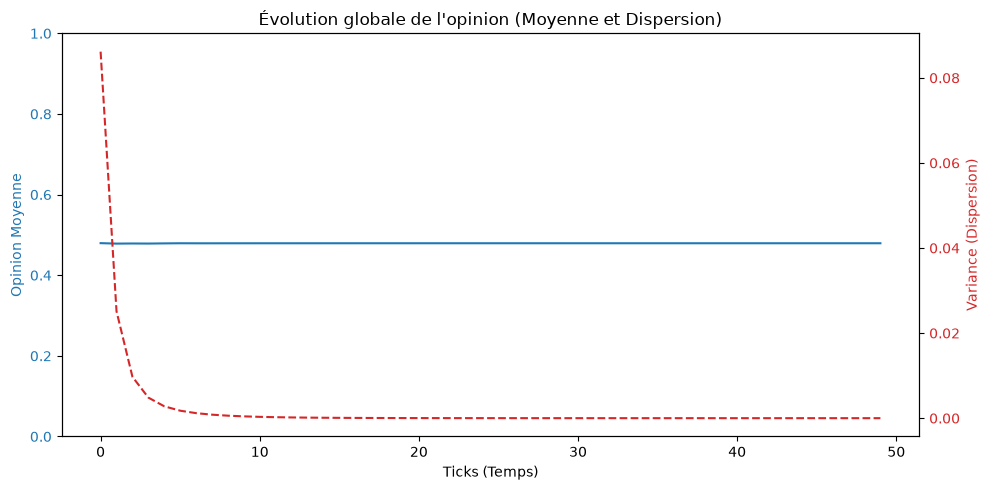

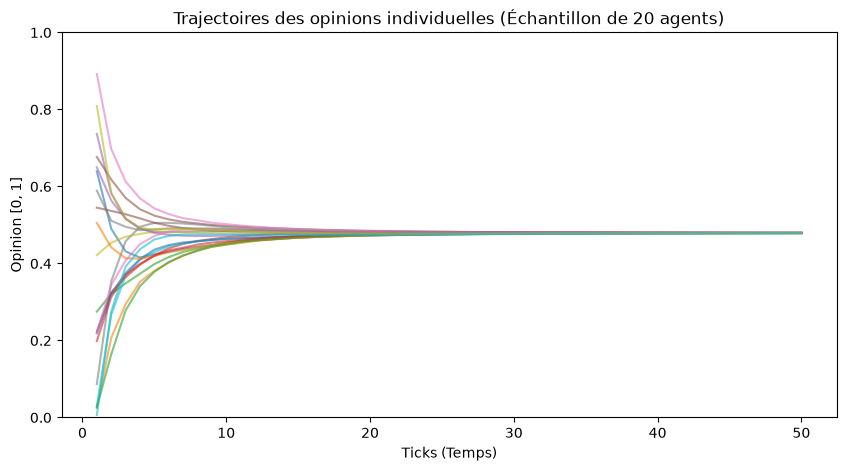

In [1]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline

class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)
        
        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation de la population : on place un agent par case
        for _, (x, y) in self.grid.coord_iter():
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")

# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 0.5  # Modifiez alpha pour observer son impact sur la vitesse de convergence
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

### On modifier Alpha pour voir son impact

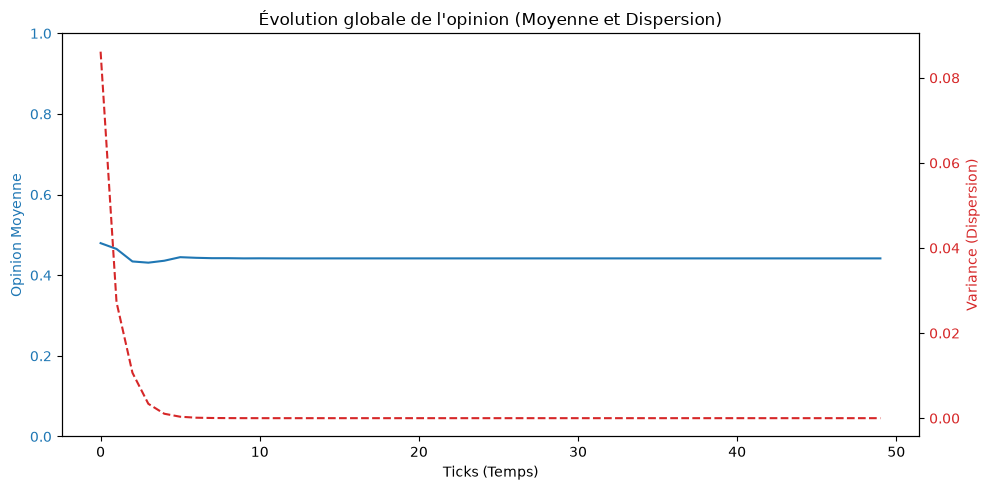

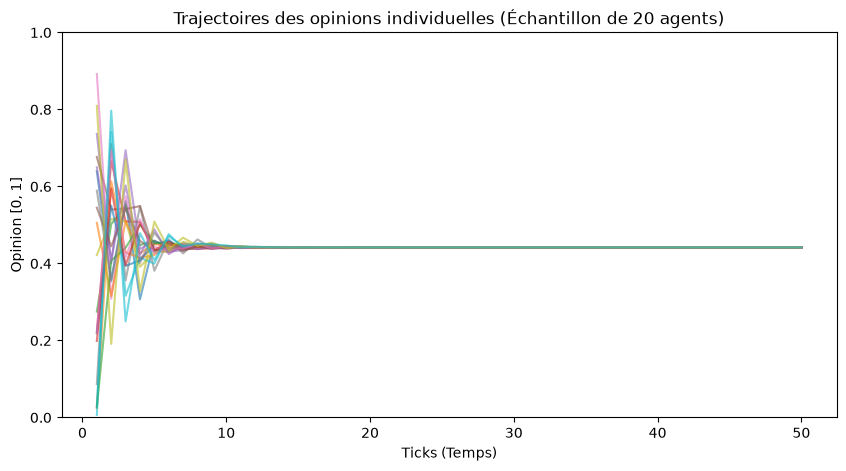

In [3]:
# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 1.5
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## 5. Questions d'analyse et de compréhension

**Compréhension théorique (Dynamique des systèmes complexes)**
* Quel est l'impact précis du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement sur le graphique si $\alpha$ est très proche de 0, ou à l'inverse, égal à 1 ?
* Dans le modèle actuel, le système finit presque toujours par converger vers un consensus global. Quel mécanisme mathématique de la méthode `step()` (mise à jour de l'opinion) rend la polarisation ou la création de groupes impossible à long terme avec cette configuration exacte ?
* En vous basant sur le protocole ODD, expliquez avec vos propres mots comment la notion d'"émergence" se manifeste dans les graphiques que vous avez générés. 

**Technique et manipulation de Mesa 3**
* Comment l'activation des agents est-elle gérée dans la nouvelle syntaxe de Mesa 3 (`self.agents.shuffle_do("step")`) par rapport aux itérations classiques sur des listes ? Quel est l'intérêt de l'ordre aléatoire ici ?
* Expliquez la différence entre `model_reporters` et `agent_reporters` lors de l'instanciation du `DataCollector`. Pourquoi est-il indispensable d'utiliser les deux pour observer à la fois le consensus et la dispersion ?
* Si un agent se trouve sur le bord de la grille (par exemple en `x=0`), comment le paramètre `torus=True` du `MultiGrid` affecte-t-il la récupération de ses voisins ?

**Ouverture et esprit critique (Pour aller plus loin)**
* Comment modifieriez-vous le code de l'agent pour introduire un "biais de confirmation" (c'est-à-dire qu'un agent n'est influencé par un voisin que si l'écart entre leurs deux opinions est inférieur à un seuil de tolérance $\epsilon$) ? Quel phénomène social émergerait alors ?
* Si nous devions modéliser un véritable réseau social (comme un graphe d'abonnés) plutôt qu'une grille spatiale, quelle structure topologique de Mesa utiliseriez-vous pour modéliser des "influenceurs" très connectés face à des utilisateurs isolés ?

A vous ....

## Reponses aux questions d'analyse et de comprehension

### Comprehension theorique (dynamique des systemes complexes)

1. **Role de $\alpha$.** Dans la regle $o_i^{t+1}=(1-\alpha)o_i^t+\alpha\bar{o}_{N_i}^t$, $\alpha$ determine la part de l'opinion moyenne des voisins utilisée a chaque mise a jour. Pour $\alpha$ proche de 0, chaque d?placement est petit : les trajectoires changent lentement et la dispersion diminue lentement. Pour $\alpha=1$, l'agent prend directement la moyenne de ses voisins a chaque activation, ce qui accelére genéralement le lissage. Comme les agents sont actives sequentiellement dans un ordre aléatoire, ces mises a jour utilisent aussi des opinions déja modifiées pendant le tick ; $\alpha=1$ ne signifie donc pas necessairement que tout le monde atteint le meme consensus en un seul tick.

2. **Pourquoi la polarisation ne se maintient pas ici.** Chaque opinion mise a jour est une combinaison convexe de l'opinion de l'agent et de la moyenne de ses voisins, avec des poids non negatifs qui totalisent 1 puisque $0\leq\alpha\leq1$. L'agent se rapproche donc de ses voisins au lieu de s'en éloigner. La grille torique est connectée et les interactions ne sont soumises ? aucun seuil : les influences se propagent entre les regions, ce qui lisse progressivement les ecarts et conduit normalement a un consensus. Il n'y a ni rejet des opinions éloignées, ni influence negative, ni separation durable des groupes.

3. **?mergence dans les graphiques.** Aucune regle ne fixe une opinion collective ni ne demande aux agents de s'accorder. Pourtant, les échanges locaux repétés font diminuer la variance et rapprochent les trajectoires individuelles. Le consensus visible a l'échelle de la population est donc un résultat collectif qui émerge des interactions locales, et non une consigne centrale. La valeur exacte du consensus dépend des opinions initiales et du déroulement des mises a jour.

### Technique et manipulation de Mesa 3

4. **Activation avec `shuffle_do`.** `self.agents.shuffle_do("step")` demande a Mesa d'appeler `step()` sur les agents du modéle, aprés les avoir melangés dans un ordre aléatoire. Une boucle classique sur une liste dans un ordre fixe privilégierait toujours les memes agents en debut de parcours. Le melange reduit ce biais et évite d'imposer un ordre d'influence systématique ; avec les mises a jour immédiates de ce modele, l'ordre de ce tick peut toutefois influer sur les valeurs intermediaires et le resultat d'une simulation donnée.

5. **`model_reporters` et `agent_reporters`.** Les `model_reporters` calculent des indicateurs pour le systeme entier a chaque collecte : ici, l'opinion moyenne et la variance. Les `agent_reporters` enregistrent les variables de chaque agent, ici son opinion. Les indicateurs globaux montrent l'évolution generale et la dispersion, tandis que les donnees individuelles permettent d'observer les trajectoires et de voir si des groupes se forment. Les deux niveaux sont complémentaires : une moyenne seule peut cacher des sous-groupes distincts.

6. **Effet de `torus=True`.** Les bords opposés sont raccordés : un agent placé prés de $x=0$ peut avoir comme voisins des agents prés de $x=\text{width}-1$ (et de meme verticalement). La grille n'a donc pas de bord qui coupe les relations ; les voisinages de Moore comprennent les positions adjacentes en diagonale ainsi qu'horizontalement et verticalement, avec raccordement autour de la grille.

### Ouverture et esprit critique

7. **Biais de confirmation et réseau social.** Pour introduire un seuil de tolérance $\epsilon$, on peut d'abord filtrer les voisins, par exemple `accepted = [n for n in neighbors if abs(n.opinion - self.opinion) <= epsilon]`, puis calculer la moyenne seulement sur `accepted` et appliquer la meme regle de rapprochement si cette liste n'est pas vide. Cette homophilie peut empecher la transmission entre opinions trop éloignées et faire apparaitre des groupes ou des consensus locaux séparés, donc une polarisation persistante selon $\epsilon$ et l'état initial. Pour représenter un réseau social avec des utilisateurs plus ou moins connectés, Mesa fournit `NetworkGrid`, qui associe les agents aux niuds d'un graphe NetworkX. On peut creer un graphe avec quelques niuds de degré élevé (influenceurs) et d'autres de faible degré ou isolés ; ces degrés représentent le nombre de connexions, sans presumer a eux seuls de l'influence réelle d'un utilisateur.
